# 01 - Data preparation and exploratory analysis

**Project:** cardiovascular risk screening from 8 routine measurements.

* **Dataset A (train):** Cardiovascular Disease dataset (Kaggle, `sulianova`). Label `cardio` = disease present at the exam.
* **Dataset B (test):** Framingham Heart Study (Kaggle copy). Label `TenYearCHD` = coronary heart disease within 10 years.
* **Shared attributes:** `age`, `sex`, `sysbp`, `diabp`, `bmi`, `smoker`, `chol_level` (1-3), `gluc_level` (1-3).

This notebook runs the raw-to-processed script, shows what it removed, and then compares the two datasets.
The comparison matters because the model is trained on A and tested on B: every difference between them
is a reason the model could lose accuracy on B.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import preprocessing as pp
import make_dataset

FIG = ROOT / "outputs" / "figures"
RES = ROOT / "outputs" / "results"
FIG.mkdir(parents=True, exist_ok=True)
RES.mkdir(parents=True, exist_ok=True)

A_COLOR, B_COLOR = "#4E79A7", "#F28E2B"          # dataset colours
HEALTHY, DISEASE = "#76B7B2", "#E15759"           # label colours
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.width", 180, "display.max_colwidth", 110)
print("project root:", ROOT.name)

project root: cardiovascular-risk-screening


## 1. Run `make_dataset` and show the cleaning log

`src/make_dataset.py` cleans Cardio one rule at a time (each rule is logged with the rows it removed),
recodes it to the shared attributes, builds Framingham's shared columns, bins cholesterol and glucose
into levels 1-3, and runs final checks. Framingham rows are never removed; out-of-range rows are only reported.

In [2]:
a, b, cleaning_log = make_dataset.main()
cleaning_log

,dataset,step,detail,rows_removed,rows_remaining
0,A,load,cardio_train.csv (semicolon separated),0,70000
1,A,drop duplicates,identical in every column except id,24,69976
2,A,convert,age days -> whole years (floor of days/365.25); BMI = weight / height^2,0,69976
3,A,remove impossible,height outside 130-210 cm,93,69883
4,A,remove impossible,weight outside 35-200 kg,18,69865
5,A,remove impossible,BMI outside 14-60,25,69840
6,A,remove impossible,systolic BP outside 70-250 mmHg,227,69613
7,A,remove impossible,diastolic BP outside 40-150 mmHg,1010,68603
8,A,remove impossible,systolic not above diastolic,88,68515
9,A,rename/recode,"gender 2 -> sex 1 (male), 1 -> 0; renamed BP, smoker, level and target columns",0,68515


In [3]:
a = pd.read_csv(ROOT / "data" / "processed" / "dataset_A.csv")
b = pd.read_csv(ROOT / "data" / "processed" / "dataset_B.csv")
print(f"A (Cardio):     {a.shape[0]:,} rows, {a.shape[1]} columns")
print(f"B (Framingham): {b.shape[0]:,} rows, {b.shape[1]} columns")
print("same columns in both files:", list(a.columns) == list(b.columns))
display(a.head(), b.head())

A (Cardio):     68,515 rows, 10 columns
B (Framingham): 4,238 rows, 10 columns
same columns in both files: True


,age,sex,sysbp,diabp,bmi,smoker,chol_level,gluc_level,target,source
0,50,1,110,80,21.967120,0,1,1,0,cardio
1,55,0,140,90,34.927679,0,3,1,1,cardio
2,51,0,130,70,23.507805,0,3,1,1,cardio
3,48,1,150,100,28.710479,0,1,1,1,cardio
4,47,0,100,60,23.011177,0,1,1,0,cardio


,age,sex,sysbp,diabp,bmi,smoker,chol_level,gluc_level,target,source
0,39,1,106.0,70.0,26.97,0,1.0,1.0,0,framingham
1,46,0,121.0,81.0,28.73,0,3.0,1.0,0,framingham
2,48,1,127.5,80.0,25.34,1,3.0,1.0,0,framingham
3,61,0,150.0,95.0,28.58,1,2.0,2.0,1,framingham
4,46,0,130.0,84.0,23.10,1,3.0,1.0,0,framingham


## 1b. Summary statistics

Descriptive statistics for every shared attribute, before any plots:

* **Numeric attributes** (`age`, `sysbp`, `diabp`, `bmi`): count, mean, standard deviation, minimum, quartiles and maximum, for A and for B.
* **Healthy vs disease**: the mean of each attribute in each class, and the difference. A large difference means the attribute separates the classes well.
* **Categorical attributes** (`sex`, `smoker`, `chol_level`, `gluc_level`): the share of people in each category.

Saved to `outputs/results/summary_statistics.csv`, `summary_by_class.csv` and `summary_categorical.csv`.

In [4]:
NUMERIC = pp.NUMERIC                      # age, sysbp, diabp, bmi
CATEGORICAL = pp.BINARY + pp.LEVELS        # sex, smoker, chol_level, gluc_level

# 1) numeric attributes: describe() for each dataset
stats = pd.concat({"A (Cardio)": a[NUMERIC].describe().T, "B (Framingham)": b[NUMERIC].describe().T}, names=["dataset", "attribute"])
stats["missing"] = pd.concat({"A (Cardio)": a[NUMERIC].isna().sum(), "B (Framingham)": b[NUMERIC].isna().sum()})
stats = stats.rename(columns={"50%": "median"})
stats.round(2).to_csv(RES / "summary_statistics.csv")
print("Numeric attributes")
display(stats.round(1))

Numeric attributes


count   mean   std   min    25%  median    75%    max  missing
dataset        attribute                                                                  
A (Cardio)     age        68515.0   52.8   6.8  29.0   48.0    53.0   58.0   64.0        0
               sysbp      68515.0  126.7  16.7  70.0  120.0   120.0  140.0  240.0        0
               diabp      68515.0   81.3   9.4  40.0   80.0    80.0   90.0  150.0        0
               bmi        68515.0   27.4   5.2  14.5   23.9    26.3   30.1   59.5        0
B (Framingham) age         4238.0   49.6   8.6  32.0   42.0    49.0   56.0   70.0        0
               sysbp       4238.0  132.4  22.0  83.5  117.0   128.0  144.0  295.0        0
               diabp       4238.0   82.9  11.9  48.0   75.0    82.0   89.9  142.5        0
               bmi         4219.0   25.8   4.1  15.5   23.1    25.4   28.0   56.8       19

In [5]:
# 2) mean of every attribute in each class (levels and binary columns treated as numbers: the mean of a 0/1 column is a share)
rows = []
for name, df in [("A (Cardio)", a), ("B (Framingham)", b)]:
    for col in NUMERIC + CATEGORICAL:
        healthy = df.loc[df.target == 0, col].mean(); disease = df.loc[df.target == 1, col].mean()
        rows.append({"dataset": name, "attribute": col, "mean_healthy": healthy, "mean_disease": disease,
                     "difference": disease - healthy, "difference_in_sd": (disease - healthy) / df[col].std()})
by_class = pd.DataFrame(rows)
by_class.round(3).to_csv(RES / "summary_by_class.csv", index=False)
print("Mean by class (difference_in_sd = difference divided by the attribute's standard deviation)")
display(by_class.pivot(index="attribute", columns="dataset", values=["mean_healthy", "mean_disease", "difference_in_sd"]).round(2))

Mean by class (difference_in_sd = difference divided by the attribute's standard deviation)


mean_healthy                mean_disease                difference_in_sd               
dataset      A (Cardio) B (Framingham)   A (Cardio) B (Framingham)       A (Cardio) B (Framingham)
attribute                                                                                         
age               51.19          48.77        54.43          54.15             0.48           0.63
bmi               26.45          25.67        28.44          26.53             0.39           0.21
chol_level         1.22           2.23         1.52           2.39             0.44           0.21
diabp             78.13          82.16        84.55          86.98             0.68           0.40
gluc_level         1.18           1.10         1.28           1.21             0.18           0.28
sex                0.35           0.41         0.35           0.53             0.01           0.25
smoker             0.09           0.49         0.08           0.52            -0.03           0.05
sysbp            119.61         130.33       133.89         143.62             0.86           0.60

In [6]:
# 3) categorical attributes: share of people in each category
cat_rows = []
for name, df in [("A (Cardio)", a), ("B (Framingham)", b)]:
    for col in CATEGORICAL:
        shares = df[col].value_counts(normalize=True, dropna=False).sort_index() * 100
        for value, pct in shares.items():
            cat_rows.append({"dataset": name, "attribute": col, "value": "missing" if pd.isna(value) else int(value), "pct": pct})
cats = pd.DataFrame(cat_rows)
cats.round(1).to_csv(RES / "summary_categorical.csv", index=False)
print("Categorical attributes, % of people (sex: 1 = male; smoker: 1 = yes; levels: 1 normal, 2 above normal, 3 well above normal)")
display(cats.pivot_table(index=["attribute", "value"], columns="dataset", values="pct", aggfunc="first").round(1))

Categorical attributes, % of people (sex: 1 = male; smoker: 1 = yes; levels: 1 normal, 2 above normal, 3 well above normal)


dataset             A (Cardio)  B (Framingham)
attribute  value                              
chol_level 1              75.0            19.6
           2              13.6            34.9
           3              11.5            44.4
           missing         NaN             1.2
gluc_level 1              85.0            82.3
           2               7.4             6.5
           3               7.6             2.0
           missing         NaN             9.2
sex        0              65.1            57.1
           1              34.9            42.9
smoker     0              91.2            50.6
           1               8.8            49.4

In [7]:
# what the summary shows, computed from the tables above
d = by_class.set_index(["dataset", "attribute"])
for ds in ["A (Cardio)", "B (Framingham)"]:
    top = d.loc[ds].difference_in_sd.abs().sort_values(ascending=False)
    print(f"{ds}: attributes that differ most between healthy and disease (in SDs): " + ", ".join(f"{k} {d.loc[(ds, k), 'difference_in_sd']:+.2f}" for k in top.index[:4]))
s = stats["mean"]
print(f"Mean age: A {s[('A (Cardio)', 'age')]:.1f}, B {s[('B (Framingham)', 'age')]:.1f}; mean systolic BP: A {s[('A (Cardio)', 'sysbp')]:.1f}, B {s[('B (Framingham)', 'sysbp')]:.1f}")
print(f"Smokers: A {a.smoker.mean()*100:.1f}%, B {b.smoker.mean()*100:.1f}%")

A (Cardio): attributes that differ most between healthy and disease (in SDs): sysbp +0.86, diabp +0.68, age +0.48, chol_level +0.44
B (Framingham): attributes that differ most between healthy and disease (in SDs): age +0.63, sysbp +0.60, diabp +0.40, gluc_level +0.28
Mean age: A 52.8, B 49.6; mean systolic BP: A 126.7, B 132.4
Smokers: A 8.8%, B 49.4%


## 2. Class balance, A vs B

The two labels mean different things, and the positive rates differ a lot. Dataset A is close to 50% positive
because it is an exam-based sample, not a population sample. B's 10-year CHD rate is much lower.

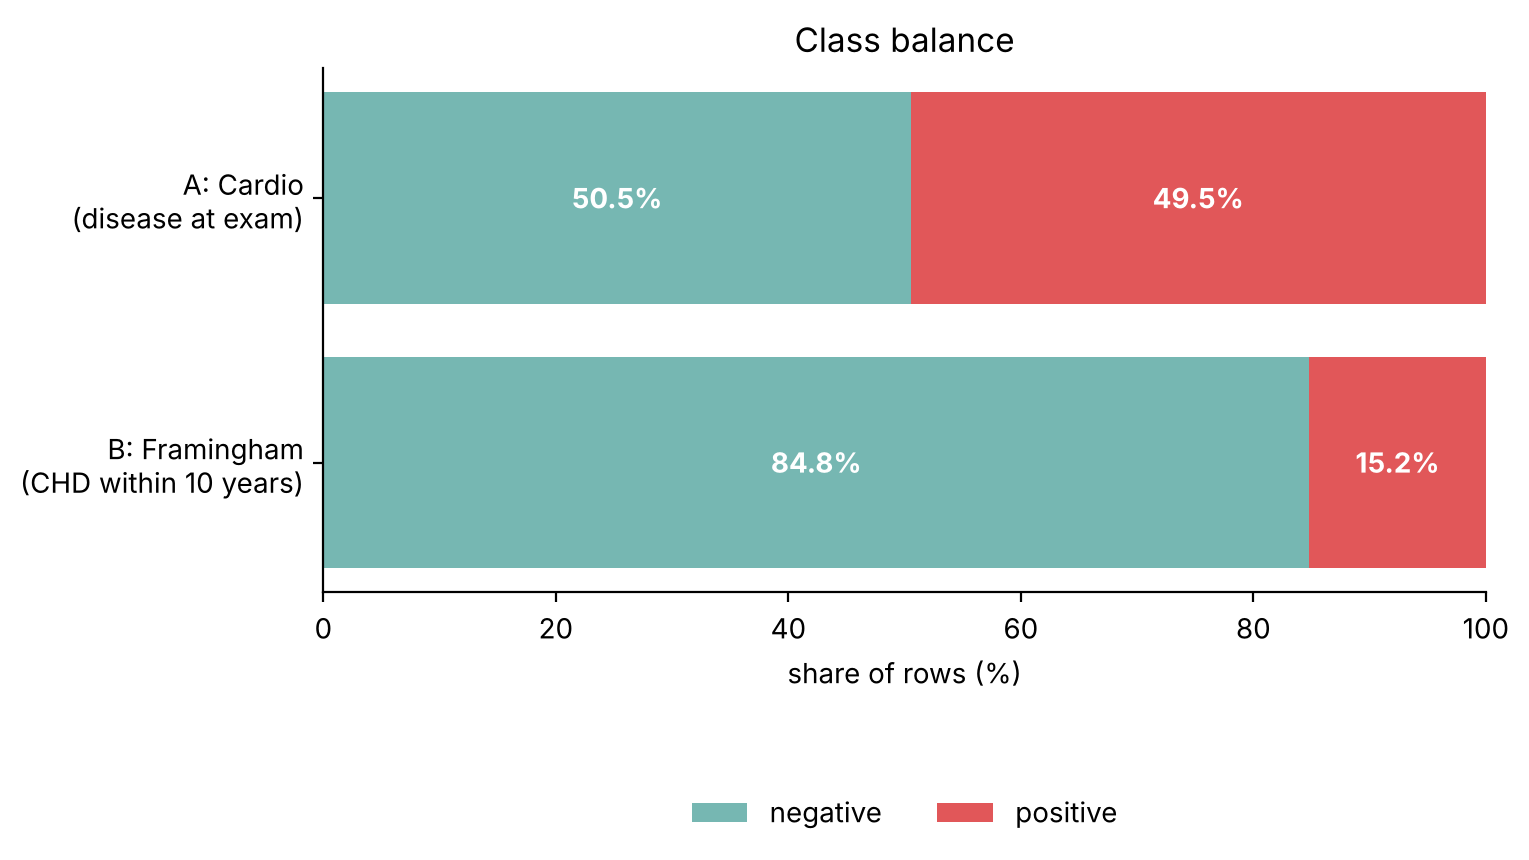

,dataset,n,positives,negatives,positive_rate
0,A (Cardio),68515,33901,34614,0.4948
1,B (Framingham),4238,644,3594,0.1520


In [8]:
balance = pd.DataFrame({
    "dataset": ["A (Cardio)", "B (Framingham)"],
    "n": [len(a), len(b)],
    "positives": [int(a.target.sum()), int(b.target.sum())],
})
balance["negatives"] = balance["n"] - balance["positives"]
balance["positive_rate"] = (balance["positives"] / balance["n"]).round(4)
balance.to_csv(RES / "class_balance.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
labels = ["A: Cardio\n(disease at exam)", "B: Framingham\n(CHD within 10 years)"]
pos = balance["positive_rate"].values * 100
ax.barh(labels, 100 - pos, color=HEALTHY, label="negative")
ax.barh(labels, pos, left=100 - pos, color=DISEASE, label="positive")
for i, p in enumerate(pos):
    ax.text(100 - p / 2, i, f"{p:.1f}%", ha="center", va="center", color="white", fontweight="bold")
    ax.text((100 - p) / 2, i, f"{100 - p:.1f}%", ha="center", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 100); ax.set_xlabel("share of rows (%)"); ax.invert_yaxis()
ax.set_title("Class balance"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.5), ncol=2, frameon=False)
fig.savefig(FIG / "eda_class_balance.png", dpi=130, bbox_inches="tight")
plt.show()
balance

## 3. Missing values per dataset

A has no missing values after cleaning (a final check in `make_dataset` enforces this). B has missing BMI,
cholesterol and glucose. Those are filled later using values learned from A only, so nothing from B leaks into training.

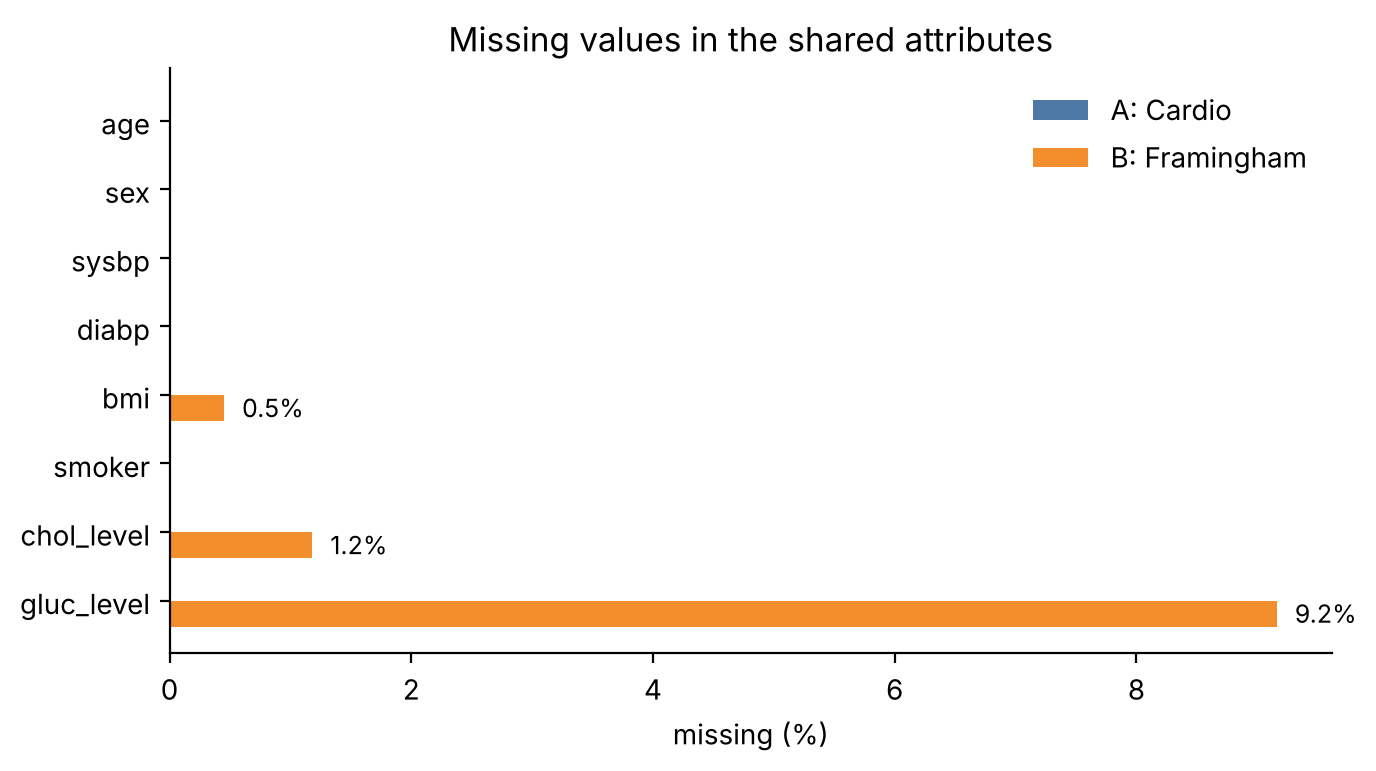

,attribute,A_missing_pct,B_missing_pct,B_missing_rows
0,age,0.0,0.00,0
1,sex,0.0,0.00,0
2,sysbp,0.0,0.00,0
3,diabp,0.0,0.00,0
4,bmi,0.0,0.45,19
5,smoker,0.0,0.00,0
6,chol_level,0.0,1.18,50
7,gluc_level,0.0,9.16,388


In [9]:
missing = pd.DataFrame({
    "attribute": pp.SHARED,
    "A_missing_pct": [round(a[c].isna().mean() * 100, 2) for c in pp.SHARED],
    "B_missing_pct": [round(b[c].isna().mean() * 100, 2) for c in pp.SHARED],
    "B_missing_rows": [int(b[c].isna().sum()) for c in pp.SHARED],
})
missing.to_csv(RES / "missing_values_pct.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(pp.SHARED)); h = 0.38
ax.barh(y - h / 2, missing["A_missing_pct"], h, color=A_COLOR, label="A: Cardio")
ax.barh(y + h / 2, missing["B_missing_pct"], h, color=B_COLOR, label="B: Framingham")
for i, v in enumerate(missing["B_missing_pct"]):
    if v > 0:
        ax.text(v + 0.15, i + h / 2, f"{v:.1f}%", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(pp.SHARED); ax.invert_yaxis()
ax.set_xlabel("missing (%)"); ax.set_title("Missing values in the shared attributes")
ax.legend(frameon=False)
fig.savefig(FIG / "eda_missing_values.png", dpi=130, bbox_inches="tight")
plt.show()
missing

## 4. Numeric distributions, healthy vs disease

Top row: A. Bottom row: B. The axis range is the same in both rows so shapes can be compared directly.
In both datasets the disease group sits higher on age and blood pressure.

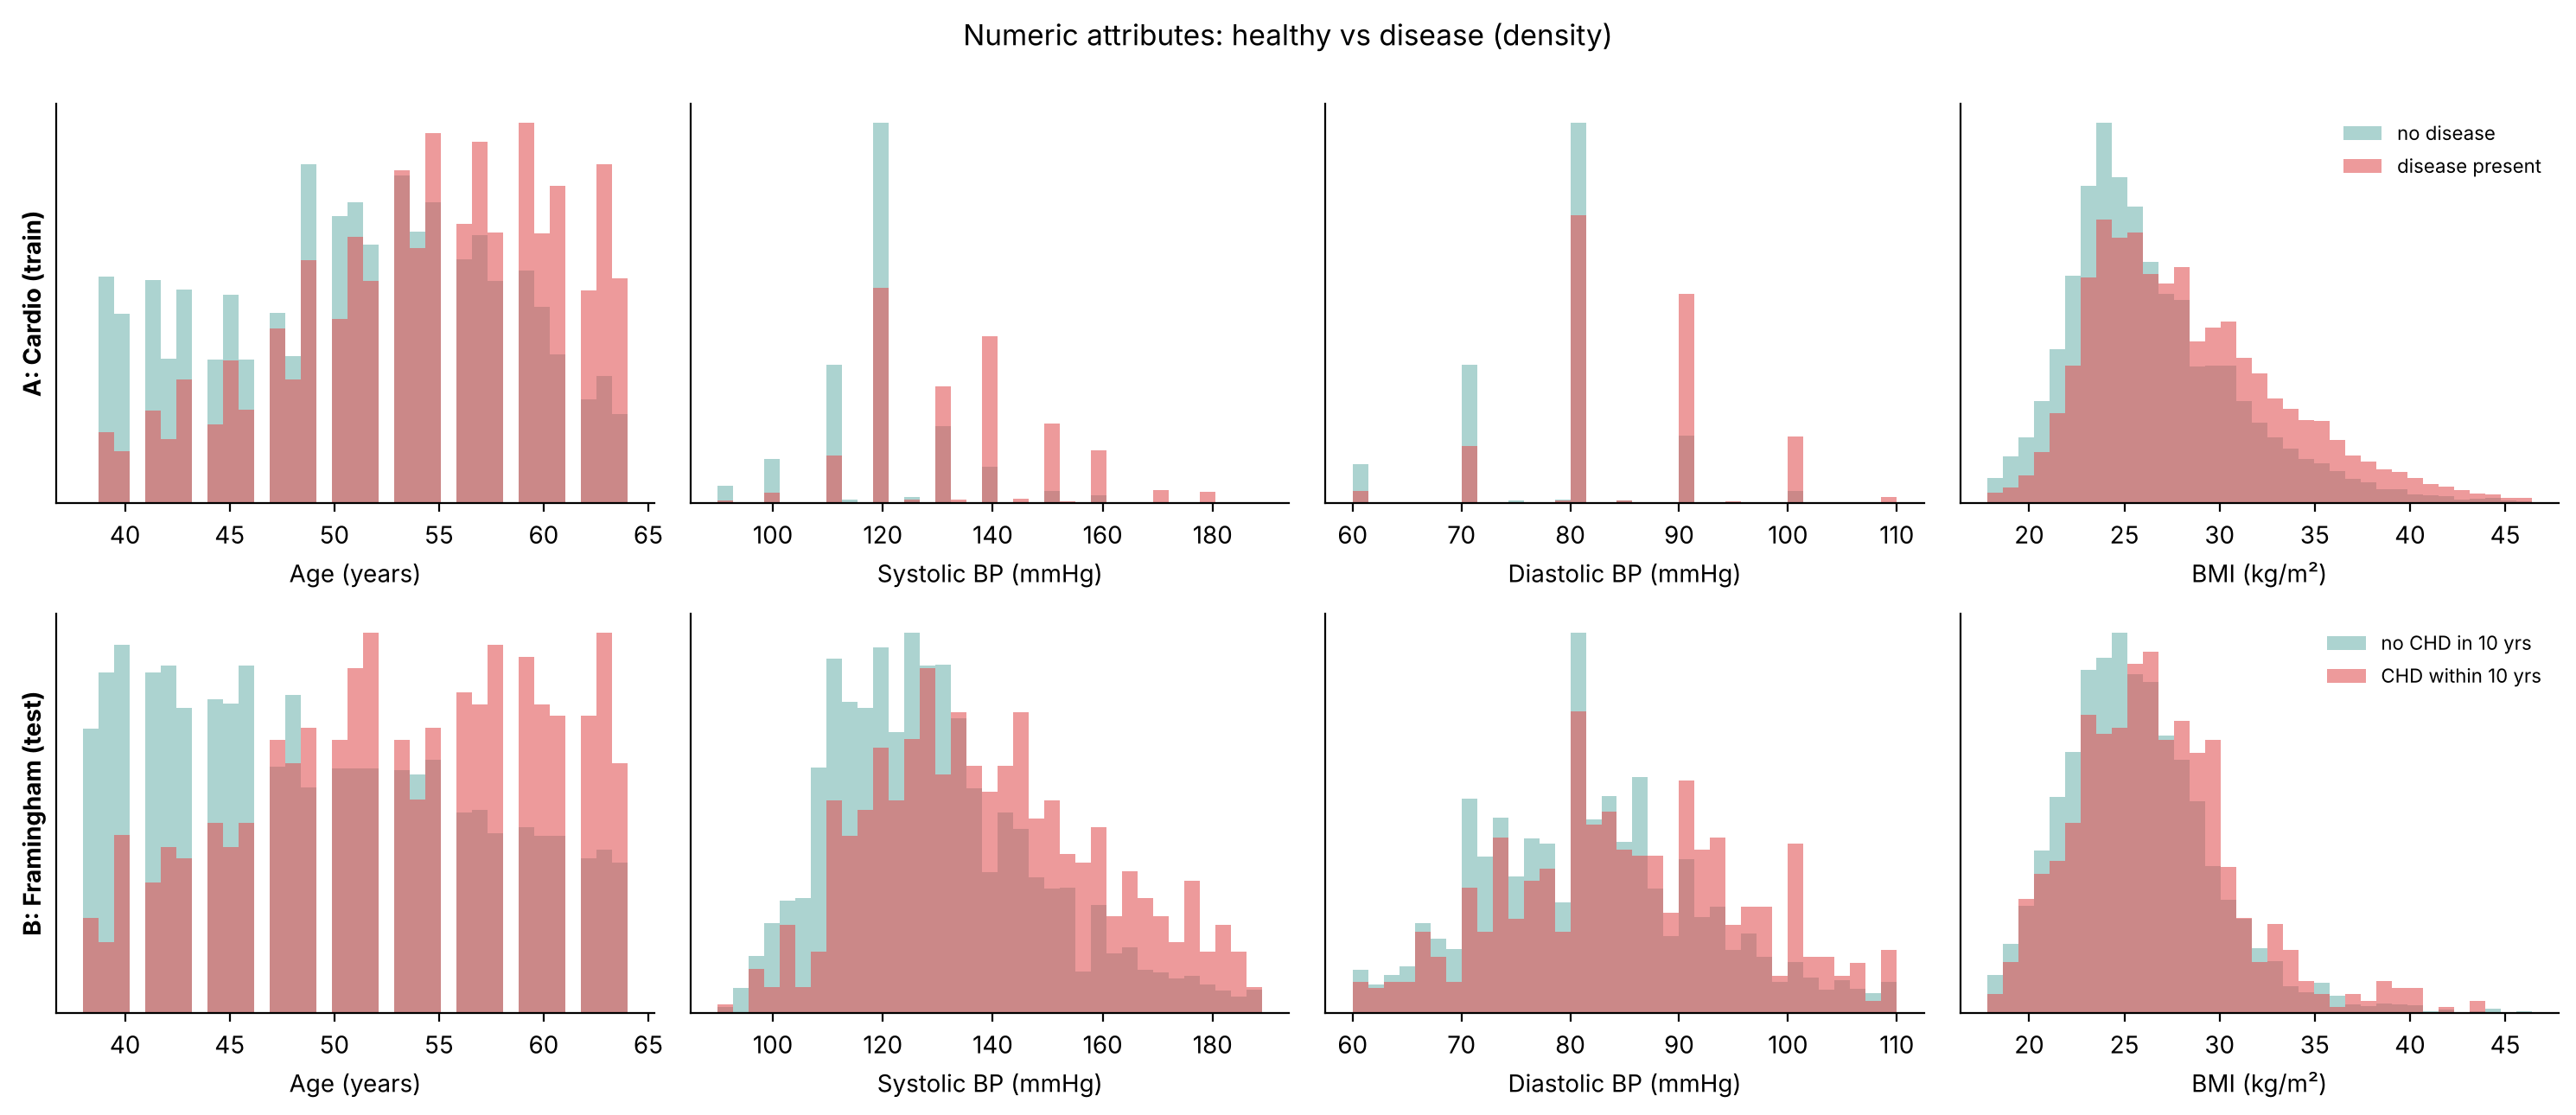

In [10]:
nice = {"age": "Age (years)", "sysbp": "Systolic BP (mmHg)", "diabp": "Diastolic BP (mmHg)", "bmi": "BMI (kg/m²)"}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for r, (name, df, labs) in enumerate([
    ("A: Cardio (train)", a, ("no disease", "disease present")),
    ("B: Framingham (test)", b, ("no CHD in 10 yrs", "CHD within 10 yrs")),
]):
    for k, c in enumerate(pp.NUMERIC):
        ax = axes[r, k]
        lo, hi = np.nanpercentile(pd.concat([a[c], b[c]]), [0.5, 99.5])
        bins = np.linspace(lo, hi, 36)
        for t, col, lab in [(0, HEALTHY, labs[0]), (1, DISEASE, labs[1])]:
            ax.hist(df.loc[df.target == t, c].dropna(), bins=bins, density=True, alpha=0.6, color=col, label=lab)
        ax.set_xlabel(nice[c]); ax.set_yticks([])
        if k == 0:
            ax.set_ylabel(name, fontweight="bold")
        if k == 3:
            ax.legend(frameon=False, fontsize=8)
fig.suptitle("Numeric attributes: healthy vs disease (density)", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "eda_numeric_distributions.png", dpi=130, bbox_inches="tight")
plt.show()

## 5. Disease rate by category

For each categorical attribute: the share of people with the label, per category, in A and B.
Watch the smoker panel: in A smokers do not show a higher disease rate, but in B they are a large group.

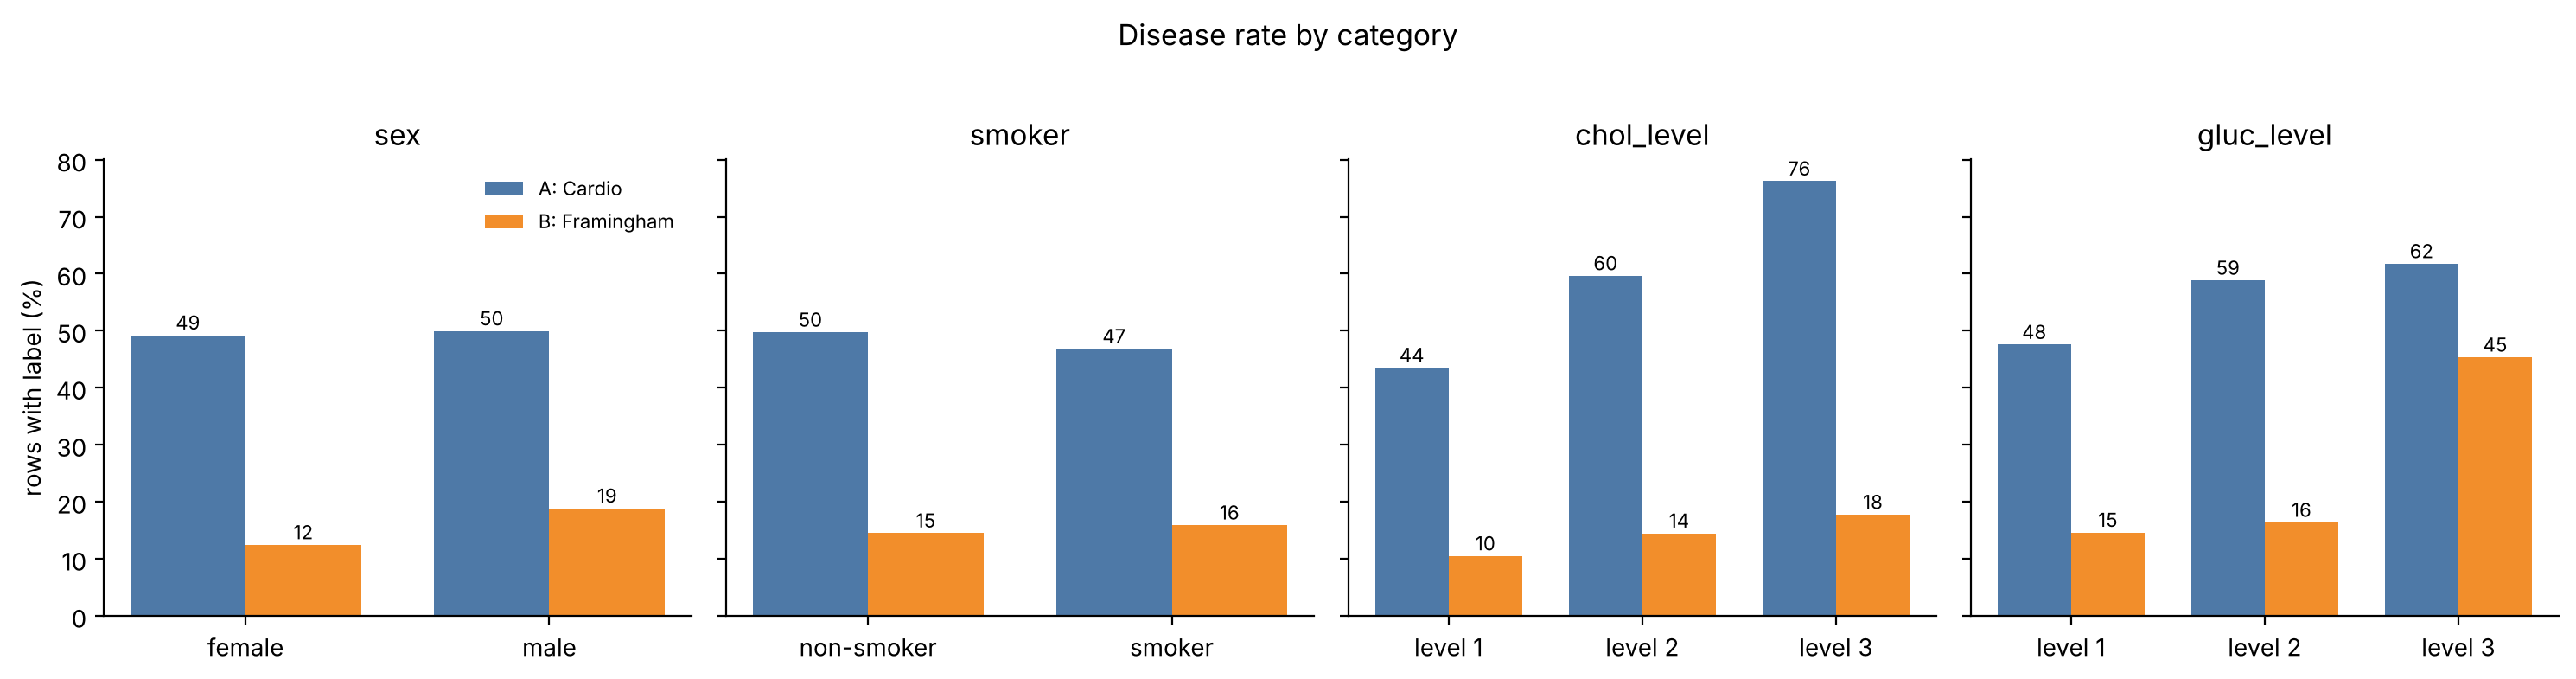

,attribute,category,n_A,disease_rate_A_pct,n_B,disease_rate_B_pct
0,sex,female,44623,49.2,2419,12.4
1,sex,male,23892,50.0,1819,18.9
2,smoker,non-smoker,62482,49.7,2144,14.5
3,smoker,smoker,6033,46.9,2094,15.9
4,chol_level,level 1,51371,43.5,829,10.5
5,chol_level,level 2,9285,59.6,1478,14.5
6,chol_level,level 3,7859,76.2,1881,17.8
7,gluc_level,level 1,58250,47.6,3489,14.6
8,gluc_level,level 2,5058,58.8,275,16.4
9,gluc_level,level 3,5207,61.7,86,45.3


In [11]:
cats = {"sex": {0: "female", 1: "male"}, "smoker": {0: "non-smoker", 1: "smoker"},
        "chol_level": {1: "level 1", 2: "level 2", 3: "level 3"}, "gluc_level": {1: "level 1", 2: "level 2", 3: "level 3"}}
rows = []
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, (c, names) in zip(axes, cats.items()):
    keys = list(names)
    ra = [a.loc[a[c] == k, "target"].mean() * 100 for k in keys]
    rb = [b.loc[b[c] == k, "target"].mean() * 100 for k in keys]
    na = [int((a[c] == k).sum()) for k in keys]
    nb_ = [int((b[c] == k).sum()) for k in keys]
    x = np.arange(len(keys)); w = 0.38
    ax.bar(x - w / 2, ra, w, color=A_COLOR, label="A: Cardio")
    ax.bar(x + w / 2, rb, w, color=B_COLOR, label="B: Framingham")
    for i in range(len(keys)):
        ax.text(x[i] - w / 2, ra[i] + 1, f"{ra[i]:.0f}", ha="center", fontsize=8)
        ax.text(x[i] + w / 2, rb[i] + 1, f"{rb[i]:.0f}", ha="center", fontsize=8)
        rows.append({"attribute": c, "category": names[keys[i]], "n_A": na[i], "disease_rate_A_pct": round(ra[i], 1),
                     "n_B": nb_[i], "disease_rate_B_pct": round(rb[i], 1)})
    ax.set_xticks(x); ax.set_xticklabels(list(names.values())); ax.set_title(c)
axes[0].set_ylabel("rows with label (%)"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Disease rate by category", y=1.02)
fig.tight_layout()
fig.savefig(FIG / "eda_categorical_disease_rate.png", dpi=130, bbox_inches="tight")
plt.show()
pd.DataFrame(rows)

## 6. Correlation heatmaps

Pearson correlations among the shared attributes and the label (levels are treated as ordered numbers).

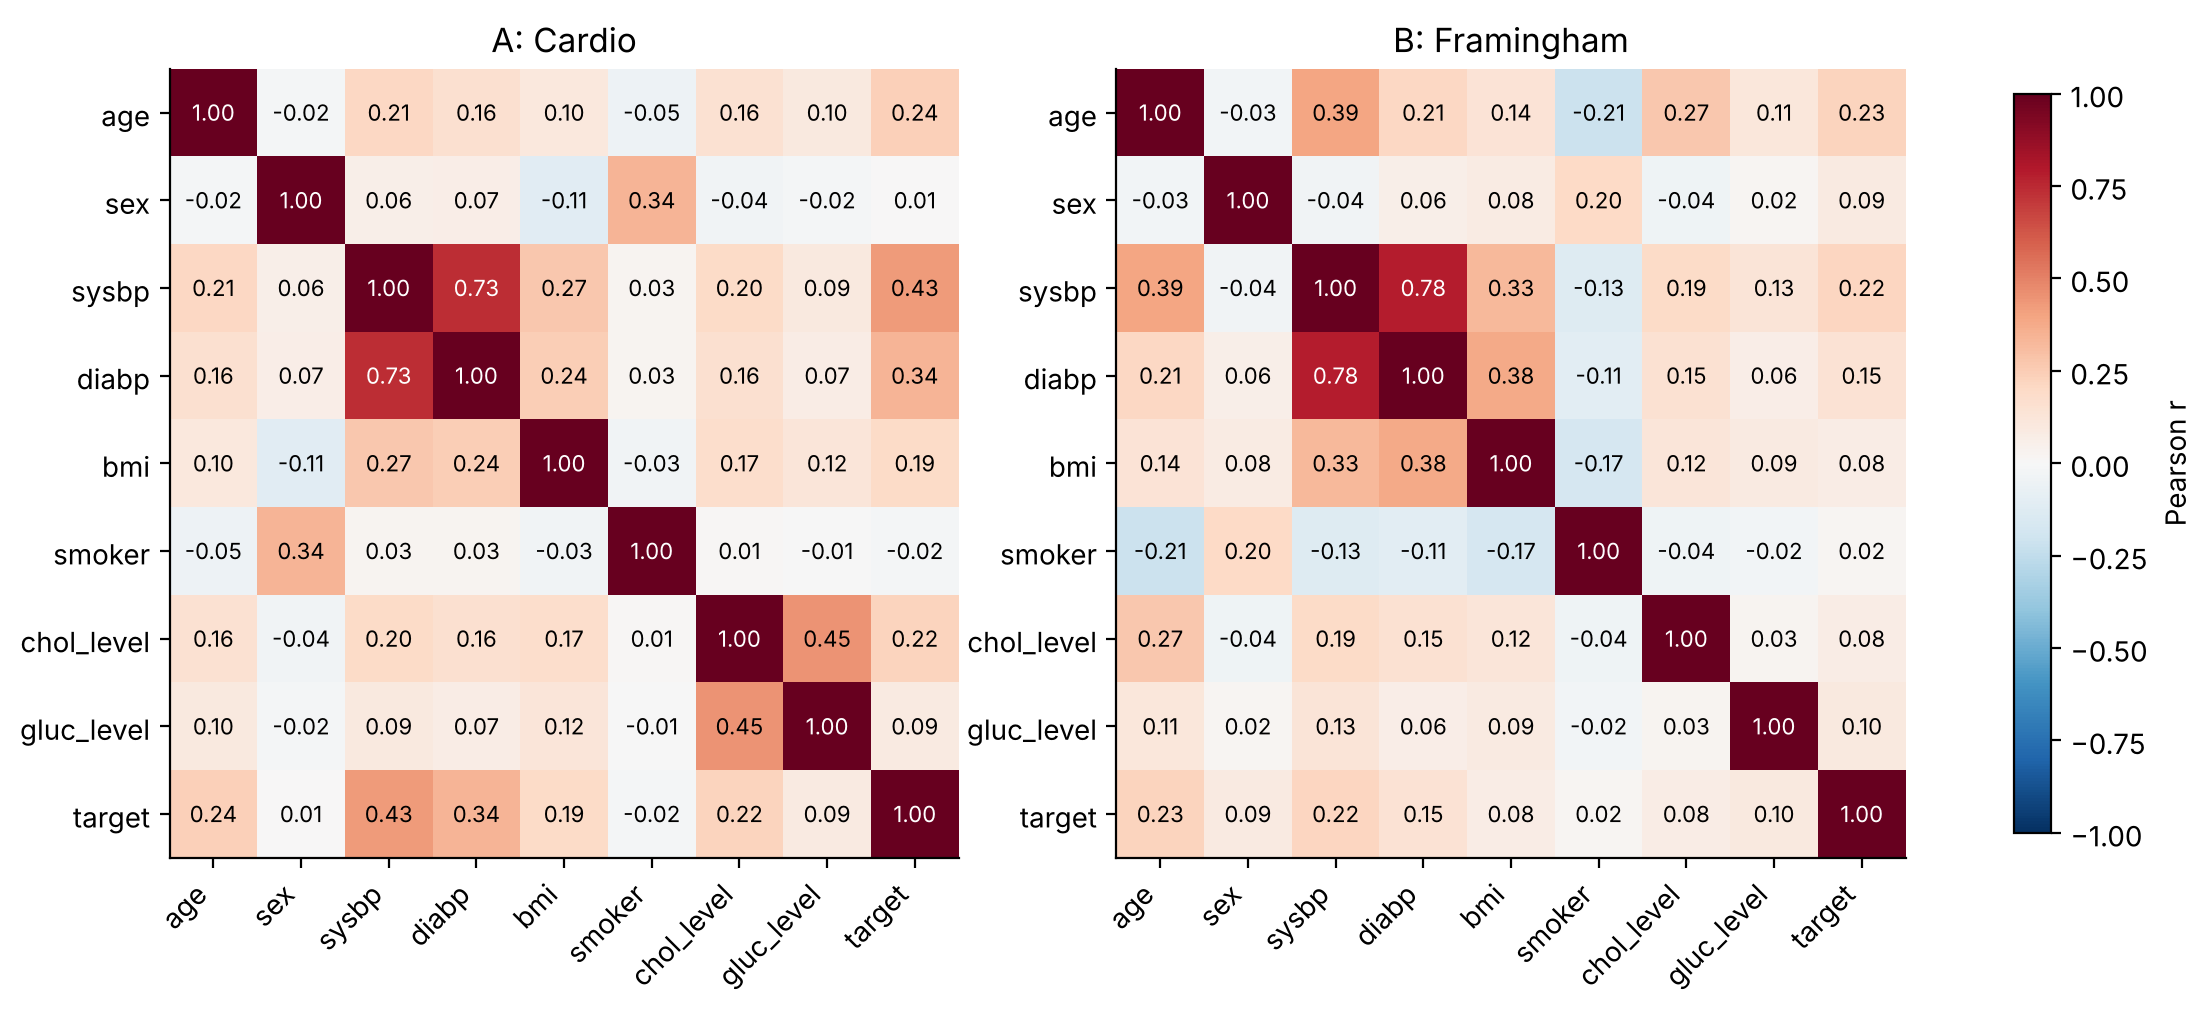

Correlation with the label, strongest first


,A,B
sysbp,0.428,0.216
diabp,0.341,0.145
age,0.239,0.225
chol_level,0.221,0.076
bmi,0.193,0.075
gluc_level,0.089,0.101
smoker,-0.016,0.019
sex,0.007,0.088


In [12]:
corr_a = a[pp.SHARED + ["target"]].corr()
corr_b = b[pp.SHARED + ["target"]].corr()
corr_a.round(4).to_csv(RES / "correlation_matrix_A.csv")
corr_b.round(4).to_csv(RES / "correlation_matrix_B.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, cm, title in [(axes[0], corr_a, "A: Cardio"), (axes[1], corr_b, "B: Framingham")]:
    im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns)
    for i in range(len(cm)):
        for j in range(len(cm)):
            v = cm.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else "black")
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8, label="Pearson r")
fig.savefig(FIG / "eda_correlation_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()
print("Correlation with the label, strongest first")
display(pd.DataFrame({"A": corr_a["target"].drop("target"), "B": corr_b["target"].drop("target")})
        .sort_values("A", key=abs, ascending=False).round(3))

## 7. A vs B comparison

Distribution shift between train and test. The table gives, for the numeric attributes, the Kolmogorov-Smirnov
statistic (0 = identical distributions, 1 = completely different), and for the categorical attributes the share in each category.
The last block checks blood-pressure rounding, because Cardio's readings look much more rounded than Framingham's.

In [13]:
ab = []
for c in pp.NUMERIC:
    x, y = a[c].dropna(), b[c].dropna()
    ks = ks_2samp(x, y)
    ab.append({"attribute": c, "kind": "numeric", "level": np.nan, "mean_A": x.mean(), "mean_B": y.mean(),
               "sd_A": x.std(), "sd_B": y.std(), "ks_statistic": ks.statistic, "ks_pvalue": ks.pvalue})
for c, names in cats.items():
    for k in names:
        ab.append({"attribute": c, "kind": "category share", "level": k,
                   "share_A": (a[c] == k).sum() / a[c].notna().sum(), "share_B": (b[c] == k).sum() / b[c].notna().sum()})
for c in ["sysbp", "diabp"]:
    ab.append({"attribute": c, "kind": "rounding (multiple of 10)", "level": np.nan,
               "share_A": (a[c] % 10 == 0).mean(), "share_B": (b[c] % 10 == 0).mean()})
ab.append({"attribute": "sysbp = 120 and diabp = 80", "kind": "rounding (exact value)", "level": np.nan,
           "share_A": ((a.sysbp == 120) & (a.diabp == 80)).mean(), "share_B": ((b.sysbp == 120) & (b.diabp == 80)).mean()})
ab.append({"attribute": "age above A's maximum", "kind": "range", "level": np.nan,
           "share_A": 0.0, "share_B": (b.age > a.age.max()).mean()})
ab = pd.DataFrame(ab)
ab.round(4).to_csv(RES / "ab_comparison.csv", index=False)
print("Numeric attributes")
display(ab[ab.kind == "numeric"][["attribute", "mean_A", "mean_B", "sd_A", "sd_B", "ks_statistic", "ks_pvalue"]].round(3))
print("Category shares")
display(ab[ab.kind == "category share"][["attribute", "level", "share_A", "share_B"]].round(3))
print("Rounding and range")
display(ab[ab.kind.str.startswith(("rounding", "range"))][["attribute", "kind", "share_A", "share_B"]].round(3))

Numeric attributes


,attribute,mean_A,mean_B,sd_A,sd_B,ks_statistic,ks_pvalue
0,age,52.792,49.585,6.764,8.572,0.234,0.0
1,sysbp,126.674,132.352,16.680,22.038,0.261,0.0
2,diabp,81.304,82.893,9.423,11.911,0.255,0.0
3,bmi,27.435,25.802,5.166,4.080,0.137,0.0


Category shares


,attribute,level,share_A,share_B
4,sex,0.0,0.651,0.571
5,sex,1.0,0.349,0.429
6,smoker,0.0,0.912,0.506
7,smoker,1.0,0.088,0.494
8,chol_level,1.0,0.750,0.198
9,chol_level,2.0,0.136,0.353
10,chol_level,3.0,0.115,0.449
11,gluc_level,1.0,0.850,0.906
12,gluc_level,2.0,0.074,0.071
13,gluc_level,3.0,0.076,0.022


Rounding and range


,attribute,kind,share_A,share_B
14,sysbp,rounding (multiple of 10),0.971,0.121
15,diabp,rounding (multiple of 10),0.971,0.148
16,sysbp = 120 and diabp = 80,rounding (exact value),0.343,0.005
17,age above A's maximum,range,0.000,0.039


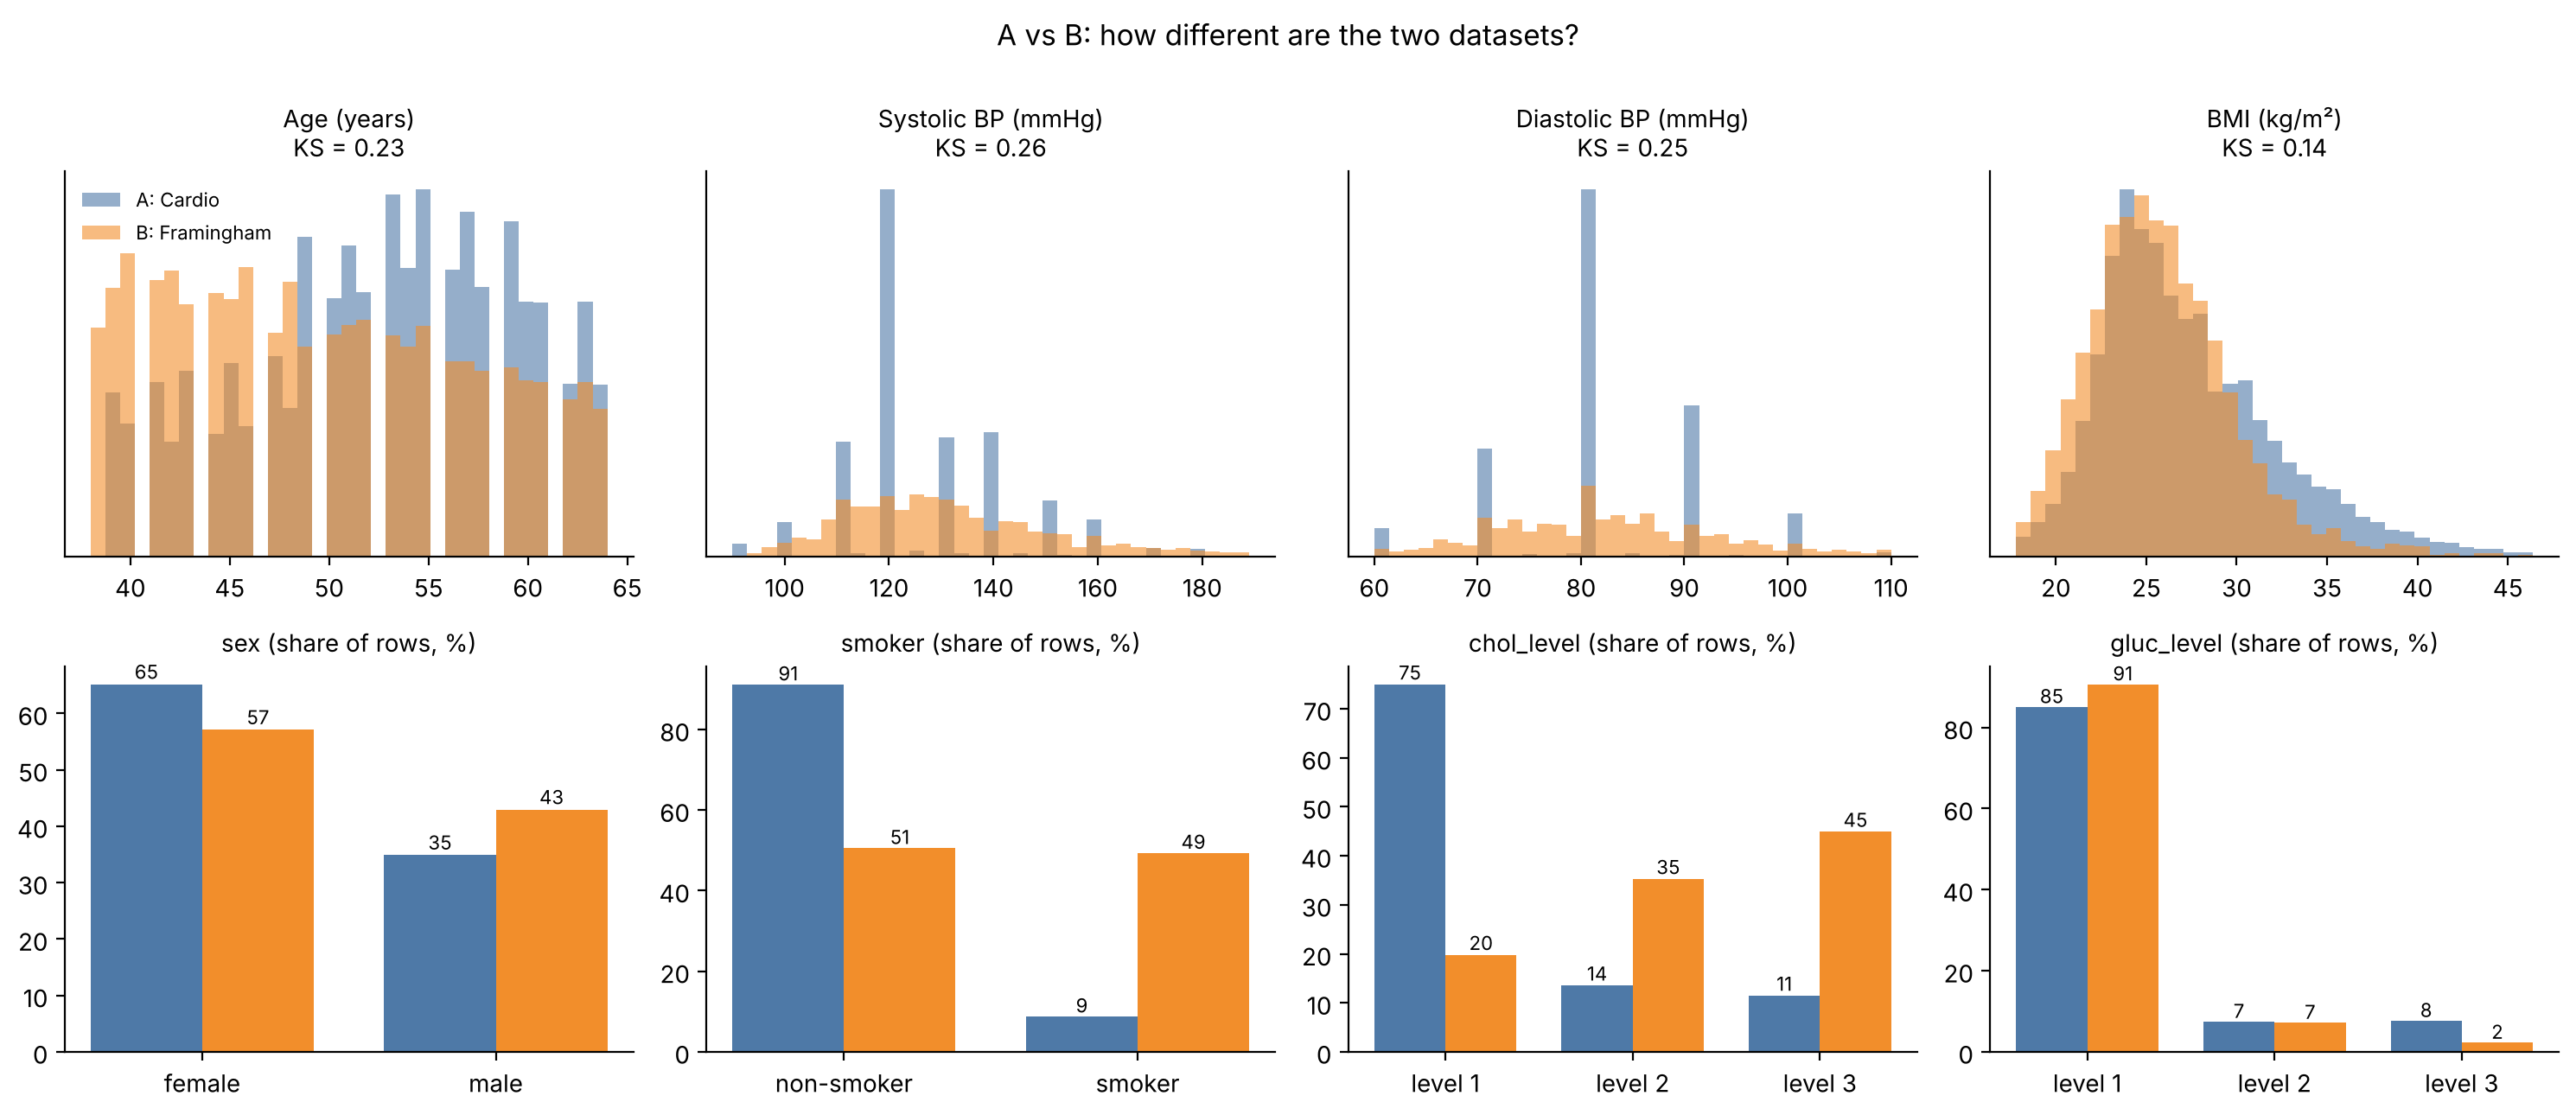

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for k, c in enumerate(pp.NUMERIC):
    ax = axes[0, k]
    lo, hi = np.nanpercentile(pd.concat([a[c], b[c]]), [0.5, 99.5])
    bins = np.linspace(lo, hi, 36)
    ax.hist(a[c].dropna(), bins=bins, density=True, alpha=0.6, color=A_COLOR, label="A: Cardio")
    ax.hist(b[c].dropna(), bins=bins, density=True, alpha=0.6, color=B_COLOR, label="B: Framingham")
    ks_val = ab.loc[(ab.attribute == c) & (ab.kind == "numeric"), "ks_statistic"].iloc[0]
    ax.set_title(f"{nice[c]}\nKS = {ks_val:.2f}", fontsize=10); ax.set_yticks([])
    if k == 0:
        ax.legend(frameon=False, fontsize=8)
for k, (c, names) in enumerate(cats.items()):
    ax = axes[1, k]
    keys = list(names)
    sa = ab[(ab.attribute == c) & (ab.kind == "category share")]["share_A"].values * 100
    sb = ab[(ab.attribute == c) & (ab.kind == "category share")]["share_B"].values * 100
    x = np.arange(len(keys)); w = 0.38
    ax.bar(x - w / 2, sa, w, color=A_COLOR); ax.bar(x + w / 2, sb, w, color=B_COLOR)
    for i in range(len(keys)):
        ax.text(x[i] - w / 2, sa[i] + 1, f"{sa[i]:.0f}", ha="center", fontsize=8)
        ax.text(x[i] + w / 2, sb[i] + 1, f"{sb[i]:.0f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(list(names.values())); ax.set_title(f"{c} (share of rows, %)", fontsize=10)
fig.suptitle("A vs B: how different are the two datasets?", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "eda_A_vs_B.png", dpi=130, bbox_inches="tight")
plt.show()

## 8. What this means for the modelling

The numbers below are computed from the processed files.

In [15]:
sm = a.groupby("smoker").target.mean() * 100
print(f"Positive rate:       A {a.target.mean()*100:.1f}%   B {b.target.mean()*100:.1f}%")
print(f"Smokers:             A {a.smoker.mean()*100:.1f}%   B {b.smoker.mean()*100:.1f}%")
print(f"Disease rate in A:   smokers {sm[1]:.1f}%  vs non-smokers {sm[0]:.1f}%")
smb = b.groupby("smoker").target.mean() * 100
print(f"CHD rate in B:       smokers {smb[1]:.1f}%  vs non-smokers {smb[0]:.1f}%")
print(f"Cholesterol levels 1/2/3:  A {pp.level_shares(a.chol_level)}   B {pp.level_shares(b.chol_level)}")
print(f"Glucose levels 1/2/3:      A {pp.level_shares(a.gluc_level)}   B {pp.level_shares(b.gluc_level)}")
print(f"B rows with any missing shared attribute: {int(b[pp.SHARED].isna().any(axis=1).sum())} ({b[pp.SHARED].isna().any(axis=1).mean()*100:.1f}%)")

Positive rate:       A 49.5%   B 15.2%
Smokers:             A 8.8%   B 49.4%
Disease rate in A:   smokers 46.9%  vs non-smokers 49.7%
CHD rate in B:       smokers 15.9%  vs non-smokers 14.5%
Cholesterol levels 1/2/3:  A {1: 0.7498, 2: 0.1355, 3: 0.1147}   B {1: 0.1979, 2: 0.3529, 3: 0.4491}
Glucose levels 1/2/3:      A {1: 0.8502, 2: 0.0738, 3: 0.076}   B {1: 0.9062, 2: 0.0714, 3: 0.0223}
B rows with any missing shared attribute: 412 (9.7%)


**Reading these results**

* The labels differ in meaning (disease at the exam vs CHD within 10 years) and in prevalence. A cutoff learned on A will
  not mean the same thing on B, so on B the headline metrics are ROC-AUC and PR-AUC, which do not depend on a cutoff.
* Cholesterol levels are shifted: Cardio's level 1 is about three quarters of its rows, while under the clinical bands
  most of Framingham is above level 1. Experiment 2c re-bins B to match A's level shares to test how much this matters.
* Smoking is common in B and rare in A, and in A it does not raise the disease rate. Experiment 2b removes `smoker` to see its effect.
* B has missing cholesterol and glucose. Experiment 2d repeats the test on complete cases only.
* Blood pressure in A is far more rounded than in B (see the rounding rows above), which a flexible model could exploit
  in A in a way that does not carry over.